<a href="https://colab.research.google.com/github/saradom11/Simulacion-II/blob/main/Modelo_SIR_PyMC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


<div style="text-align:center; background-color:#F3E5F5; padding:24px; border-radius:15px;">
<font face="Georgia" size="6" color="#6A1B9A"><b>Estimación de parámetros del modelo SIR con PyMC</b></font><br>
</div>

**Materia**: Investigación de operaciones

**Alumna:** Arredondo Domínguez Sara Itzel

---
<font face="Georgia" size="5" color="#7B1FA2"><b>1. Bibliotecas</b></font>

Usaremos NumPy para manejar los datos, Matplotlib y Seaborn para las gráficas, SciPy para una solución numérica de referencia y PyMC para definir el modelo probabilístico y obtener muestras de la distribución posterior. ArviZ se utilizará para resumir y visualizar los resultados.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pymc as pm
import arviz as az
from scipy.integrate import odeint
from scipy.interpolate import make_interp_spline

# Configuración visual en tonos morados
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["figure.figsize"] = (9, 5.5)

# Semilla para facilitar la reproducibilidad de los resultados
np.random.seed(2026)



---
<font face="Georgia" size="5" color="#7B1FA2"><b>2. Datos y condiciones iniciales</b></font>

Se conservan los datos de infectados y las condiciones iniciales del ejercicio:

- $N=763$: tamaño total de la población.
- $I(0)=1$: número inicial de infectados.
- $R(0)=0$: número inicial de recuperados.
- $S(0)=N-I(0)-R(0)$: número inicial de susceptibles.

Así como el vector temporal definido en el notebook original, $t=\operatorname{linspace}(0,15,15)$, para mantener las mismas observaciones y tiempos.


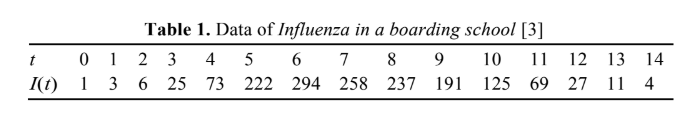

,Tiempo,Infectados observados
0,0.000000,1
1,1.071429,3
2,2.142857,6
3,3.214286,25
4,4.285714,73
5,5.357143,222
6,6.428571,294
7,7.500000,258
8,8.571429,237
9,9.642857,191


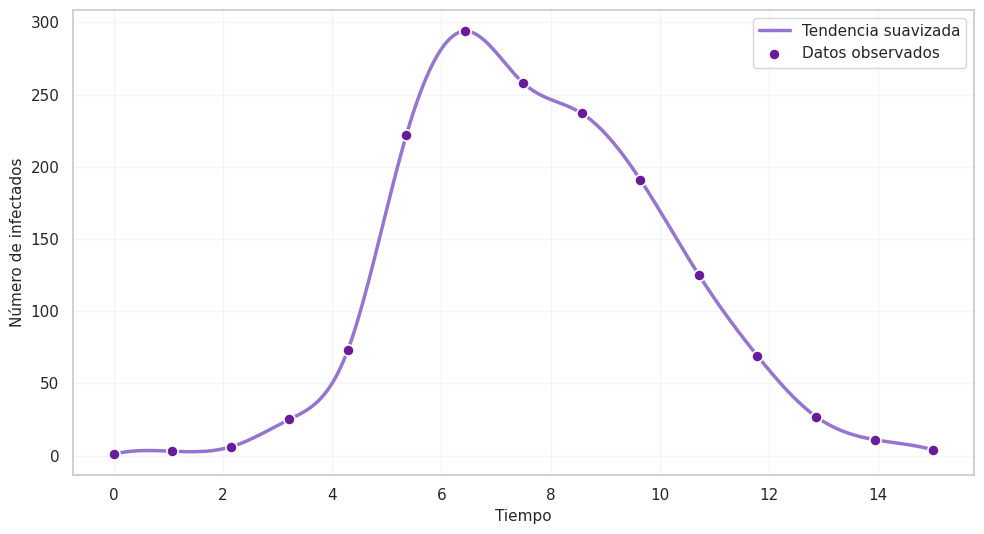

In [2]:

# Número de infectados observados en cada tiempo
datos_school = np.array([1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4],dtype=float)

# Tamaño de la población y condiciones iniciales
N = 763
I0 = 1.0
R0 = 0.0
S0 = N - I0 - R0

# Tiempos de observación: se conserva la definición del ejercicio
t_obs = np.linspace(0, 15, 15)

# Tabla de los datos utilizados
tabla_datos = pd.DataFrame({"Tiempo": t_obs,"Infectados observados": datos_school.astype(int)})
display(tabla_datos)

# Crear tiempos intermedios para suavizar visualmente la curva
t_suave = np.linspace(t_obs.min(), t_obs.max(), 300)
curva_suave = make_interp_spline(t_obs, datos_school, k=3)(t_suave)

# Evitar valores negativos generados por la interpolación
curva_suave = np.maximum(curva_suave, 0)

# Gráfica de los datos observados con una línea suavizada
plt.figure(figsize=(10, 5.5))

plt.plot(t_suave,curva_suave,color="#9575CD",linewidth=2.5,label="Tendencia suavizada")
plt.scatter(t_obs,datos_school,color="#6A1B9A",s=65,edgecolor="white",linewidth=1.2,zorder=3,label="Datos observados")
plt.xlabel("Tiempo", fontsize=11)
plt.ylabel("Número de infectados", fontsize=11)
plt.legend(frameon=True)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()



<font face="Georgia" size="5" color="#7B1FA2"><b>3. Modelo SIR</b></font>

El modelo divide a la población en tres grupos: susceptibles $S(t)$, infectados $I(t)$ y recuperados $R(t)$. Con las siguientes ecuaciones:

$$ \frac{dS}{dt}=-\beta SI,\qquad
\frac{dI}{dt}=\beta SI-\gamma I,\qquad
\frac{dR}{dt}=\gamma I $$

En la interfaz `DifferentialEquation` de PyMC se define la función de las ecuaciones diferenciales y se indica cuántos estados y parámetros contiene. Como los datos observados corresponden a infectados, la solución que se compara con los datos es $I(t)$. La función de PyMC integra los estados $S$ e $I$; no es necesario integrar $R$ para estimar estos parámetros con los datos disponibles. La interfaz de PyMC recibe los tiempos posteriores al instante inicial, por eso el ajuste usa `t_obs[1:]` y `datos_school[1:]`; la primera observación coincide con la condición inicial $I(0)=1$.


In [3]:
# Función del sistema diferencial en el formato requerido por PyMC
# y contiene los estados [S, I] y p contiene los parámetros [beta, gamma]
def sir_pymc(y, t, p):
    S = y[0]
    I = y[1]
    beta = p[0]
    gamma = p[1]
    dSdt = -beta * S * I
    dIdt = beta * S * I - gamma * I
    return [dSdt, dIdt]

# PyMC construye el integrador diferencial con:
# - func: ecuaciones del modelo
# - times: tiempos de observación
# - n_states: número de variables de estado (S e I)
# - n_theta: número de parámetros estimados (beta y gamma)
# - t0: tiempo inicial
sir_ode = pm.ode.DifferentialEquation(
    func=sir_pymc,
    times=t_obs[1:],  # PyMC recibe tiempos posteriores a t0
    n_states=2,n_theta=2,t0=0)


<font face="Georgia" size="5" color="#7B1FA2"><b>4. Definición del modelo bayesiano</b></font>

La inferencia bayesiana combina una distribución previa (*prior*) para los parámetros con una función de verosimilitud que relaciona la solución del modelo con los datos observados.

Se asignan distribuciones lognormales a $\beta$ y $\gamma$, de modo que ambos parámetros sean positivos. La desviación estándar $\sigma$ del error de observación se modela con una distribución HalfNormal. Finalmente, se supone que los datos observados fluctúan alrededor de los infectados predichos por el modelo según una distribución normal:

$$I_{\mathrm{obs},i}\sim
\mathcal{N}\left(I_{\mathrm{SIR}}(t_i;\beta,\gamma),\sigma\right)$$



In [4]:

with pm.Model() as modelo_sir:
    # Distribuciones previas positivas para los parámetros del modelo
    # Los centros se eligen como valores iniciales razonables para este ejercicio
    beta = pm.LogNormal("beta",mu=np.log(8e-4),sigma=1.0)
    gamma = pm.LogNormal("gamma",mu=np.log(0.25),sigma=0.8)

    # Incertidumbre de las observaciones, expresada en número de personas
    sigma = pm.HalfNormal("sigma", sigma=50.0)

    # Solución de las ecuaciones diferenciales para cada combinación de parámetros
    solucion_sir = sir_ode(y0=[S0, I0],theta=[beta, gamma])

    # La segunda columna corresponde al estado de infectados I(t)
    infectados_estimados = solucion_sir[:, 1]

    # Modelo de observación: los infectados registrados fluctúan alrededor de la trayectoria del modelo SIR
    observaciones = pm.Normal("observaciones",mu=infectados_estimados,sigma=sigma, observed=datos_school[1:]  # Se excluye t=0 porque es la condición inicial
                              )



---
<font face="Georgia" size="5" color="#7B1FA2"><b>5. Muestreo de la distribución posterior</b></font>

Se solicita a PyMC generar muestras de la distribución posterior de los parámetros. PyMC selecciona automáticamente un método de muestreo apropiado para el modelo; el ejemplo oficial enlazado utiliza esta misma idea al llamar a `pm.sample`.

El periodo de ajuste (*tuning*) permite que el algoritmo adapte sus pasos antes de guardar las muestras que se utilizarán para resumir los parámetros. Se usan dos cadenas independientes para facilitar la revisión de convergencia.


In [5]:

with modelo_sir:
    # El periodo de tuning adapta el muestreador
    # Las muestras posteriores se usan para estimar beta, gamma y sigma
    idata = pm.sample(draws=500,tune=500,chains=2,cores=1,target_accept=0.9,random_seed=2026,return_inferencedata=True)


Output()

---
<font face="Georgia" size="5" color="#7B1FA2"><b>6. Resumen de los parámetros estimados</b></font>

La tabla siguiente presenta estadísticas de la distribución posterior. La media resume el valor central de las muestras y los intervalos creíbles indican un rango de valores compatibles con la distribución posterior. Los diagnósticos $\hat R$ y tamaño efectivo de muestra ayudan a revisar si las cadenas han explorado adecuadamente la distribución.


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
beta,0.002034,0.000035,0.001967,0.002108,0.000001,0.000001,662.534223,685.271090,1.006169
gamma,0.415864,0.018090,0.381721,0.450912,0.000785,0.000853,564.756552,478.083035,1.000327
sigma,21.500296,5.047599,13.785125,32.658820,0.223647,0.228442,560.700062,593.844813,0.998531


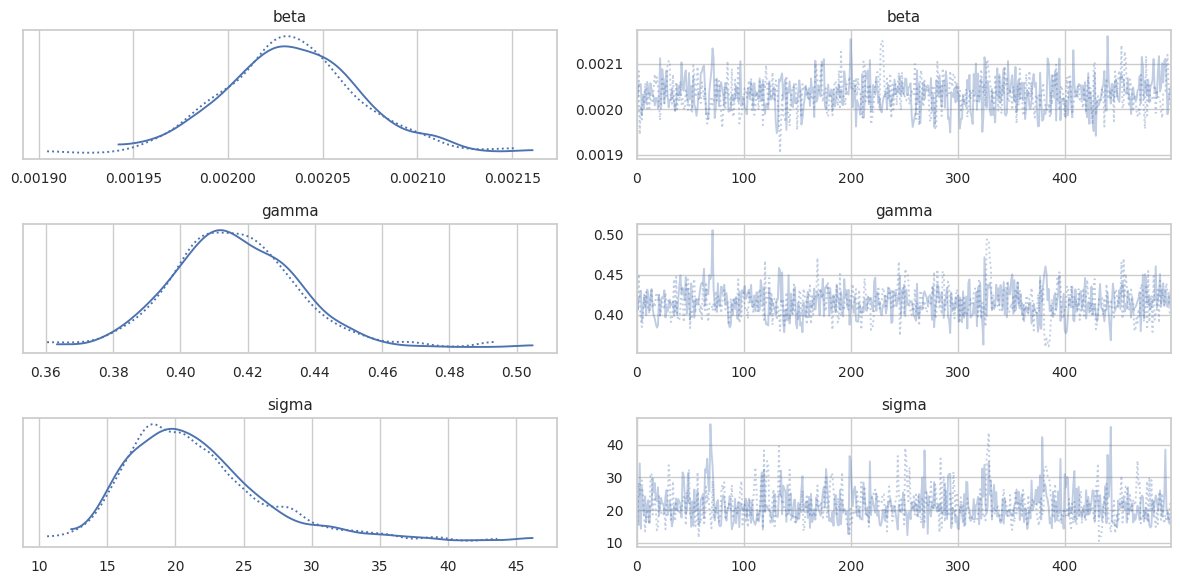

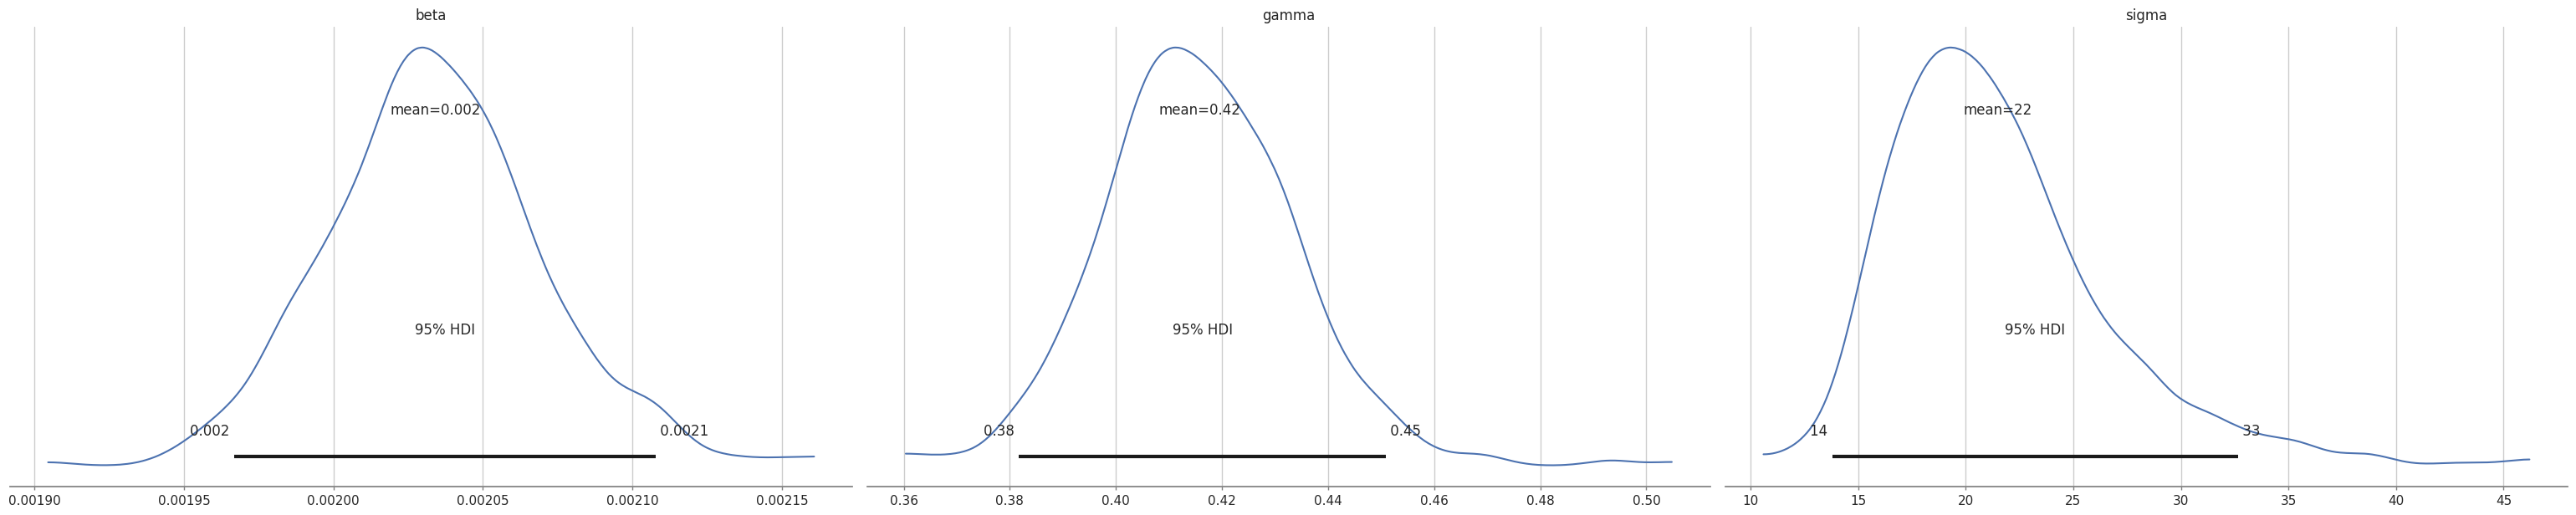

In [6]:
# Resumen posterior de los parámetros
resumen = az.summary(idata,var_names=["beta", "gamma", "sigma"],hdi_prob=0.95,round_to=6)
display(resumen)

# Diagnóstico visual de las cadenas y de las distribuciones posteriores
az.plot_trace(idata, var_names=["beta", "gamma", "sigma"])
plt.tight_layout()
plt.show()

az.plot_posterior(idata, var_names=["beta", "gamma", "sigma"], hdi_prob=0.95)
plt.tight_layout()
plt.show()


---
<font face="Georgia" size="5" color="#7B1FA2"><b>7. Comparación entre datos y modelo ajustado</b></font>

Para visualizar el ajuste, se toman las medias posteriores de
$\beta$ y $\gamma$ y se resuelve nuevamente el sistema SIR. La trayectoria de infectados se compara con los datos originales. Esta gráfica permite evaluar visualmente si el modelo reproduce el crecimiento y la disminución observados en el brote.


Beta estimado (media posterior): 0.00203412
Gamma estimado (media posterior): 0.41586403


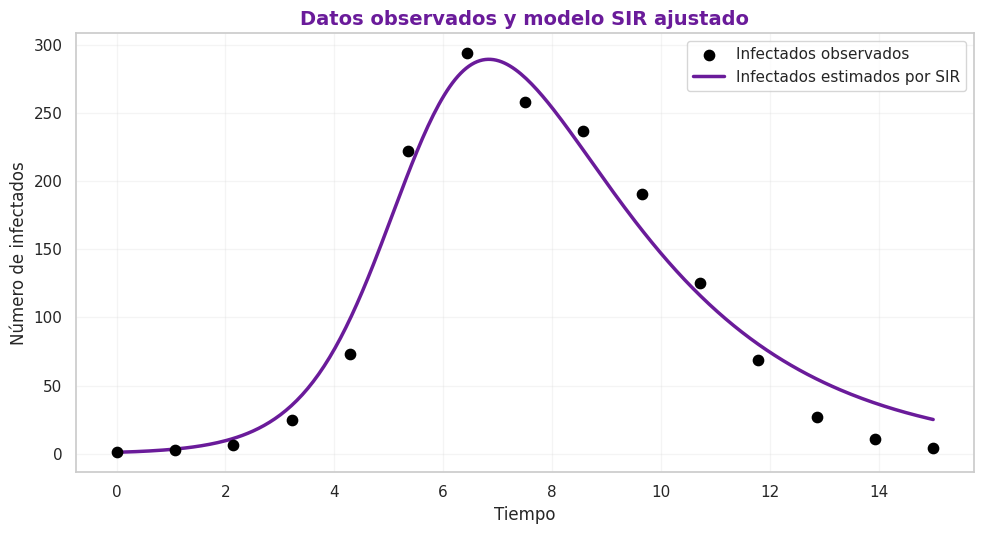

In [7]:
# Obtener las medias posteriores de los parámetros
beta_estimado = float(idata.posterior["beta"].mean().values)
gamma_estimado = float(idata.posterior["gamma"].mean().values)

print(f"Beta estimado (media posterior): {beta_estimado:.8f}")
print(f"Gamma estimado (media posterior): {gamma_estimado:.8f}")

# Solución numérica del modelo SIR para los tres estados: S, I y R
def sir_completo(estado, tiempo, beta, gamma):
    S, I, R = estado
    dSdt = -beta * S * I
    dIdt = beta * S * I - gamma * I
    dRdt = gamma * I
    return [dSdt, dIdt, dRdt]


# Resolver el modelo en los tiempos de observación
solucion_ajustada = odeint(sir_completo,[S0, I0, R0],t_obs,args=(beta_estimado, gamma_estimado))

S_ajustado = solucion_ajustada[:, 0]
I_ajustado = solucion_ajustada[:, 1]
R_ajustado = solucion_ajustada[:, 2]

# Crear una malla de tiempos más densa para dibujar curvas suaves
t_suave = np.linspace(t_obs.min(), t_obs.max(), 300)

# Resolver nuevamente el modelo usando los tiempos intermedios
solucion_suave = odeint(sir_completo,[S0, I0, R0],t_suave,args=(beta_estimado, gamma_estimado))

S_suave = solucion_suave[:, 0]
I_suave = solucion_suave[:, 1]
R_suave = solucion_suave[:, 2]

# Graficar los datos observados y la curva suave del modelo SIR
plt.figure(figsize=(10, 5.5))
plt.scatter(t_obs,datos_school,color="black",s=55,label="Infectados observados",zorder=3)
plt.plot(t_suave,I_suave,color="#6A1B9A",linewidth=2.5,label="Infectados estimados por SIR")
plt.title("Datos observados y modelo SIR ajustado",color="#6A1B9A",fontweight="bold",fontsize=14)
plt.xlabel("Tiempo")
plt.ylabel("Número de infectados")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


<font face="Georgia" size="5" color="#7B1FA2"><b>8. Interpretación y conclusión</b></font>

El ajuste bayesiano proporciona una distribución posterior para $\beta$ y $\gamma$, en lugar de un único valor sin incertidumbre. El parámetro $\beta$ controla la velocidad de transmisión en las ecuaciones utilizadas, mientras que $\gamma$ controla la velocidad a la que los infectados pasan al grupo de recuperados.

Al interpretar los resultados, se recomienda revisar tanto los intervalos creíbles como los gráficos de las cadenas. También debe comprobarse si la curva estimada sigue razonablemente a los datos observados. Si aparecen advertencias de convergencia o un ajuste visual deficiente, los resultados no deben considerarse definitivos sin revisar los supuestos, las distribuciones previas y la formulación del modelo.


**Solución final que debe reportarse.** Una vez ejecutadas las celdas, reporta las medias posteriores de `beta` y `gamma` y sus intervalos creíbles del 95 % en la tabla de `az.summary`. Esos valores no se fijan de antemano: se obtienen de las muestras calculadas por PyMC. La gráfica de ajuste permite comparar la trayectoria estimada de infectados con las observaciones.
